# Notebook 5

NEW NOTEBOOK:

* Statistics, figures and code checks
- Deliverable: finalizing figures and sample counts - checks all 3 notebooks are running correctly.

Step 1: Download CSVs with all of the data on them (include MF change) from GitHub

In [1]:
import pandas as pd
from pathlib import Path

# Download the GitHub repository
!git clone https://github.com/chelseataylor1/BMEN-600-Group-19.git

# Locate the MF CSVs folder
csv_folder = Path("/content/BMEN-600-Group-19/data/processed/OutputFromNotebook4_EHG_Dataset")

# Show all CSV files in the folder
csv_files = list(csv_folder.glob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)

Cloning into 'BMEN-600-Group-19'...
remote: Enumerating objects: 262, done.
remote: Counting objects: 100% (262/262), done.
remote: Compressing objects: 100% (243/243), done.
remote: Total 262 (delta 89), reused 5 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (262/262), 133.34 MiB | 22.52 MiB/s, done.
Resolving deltas: 100% (89/89), done.
CSV files found: 3
Notebook4c.csv
Notebook4b.csv
Notebook4a.csv


In [2]:
# Merge the 3 CSVs into one (using preganncy id as a match)

# Load all 3 CSV files
dfs = [pd.read_csv(file) for file in sorted(csv_files)]

# Match rows using pregnancy_id
df_combined = dfs[0].set_index("pregnancy_id")

for df in dfs[1:]:
    df_combined = df_combined.combine_first(
        df.set_index("pregnancy_id")
    )

# Restore pregnancy_id as a column
df_combined = df_combined.reset_index()

# Display the combined dataset
print("Total pregnancies:", len(df_combined))
print("Missing values remaining:", df_combined.isna().sum().sum())

display(df_combined)

Total pregnancies: 35
Missing values remaining: 19


,pregnancy_id,age,early_id,early_week_x,weight_early,later_id,later_week_x,weight_later,height,placenta,...,S2_change,S2_change_per_week,S3_early_MF,S3_later_MF,S3_change,S3_change_per_week,S4_early_MF,S4_later_MF,S4_change,S4_change_per_week
0,17,22,620,23.9,73,1529,31.9,81,168,end,...,0.0428,0.0053,0.4429,0.4394,-0.0035,-0.0004,0.3641,0.3544,-0.0097,-0.0012
1,18,38,656,22.4,77,1385,31.1,82,167,end,...,-0.0876,-0.0101,0.6435,0.3547,-0.2888,-0.0332,0.4768,0.3492,-0.1276,-0.0147
2,19,26,665,23.1,83,664,30.4,84,165,front,...,0.0542,0.0074,0.4427,0.8185,0.3758,0.0515,0.4262,0.5412,0.1150,0.0158
3,20,32,757,22.4,68,756,30.6,72,162,end,...,0.0289,0.0035,0.3275,0.3657,0.0382,0.0047,0.3146,0.3527,0.0381,0.0046
4,21,29,774,25.0,77,775,31.1,83,171,front,...,-0.0013,-0.0002,0.5112,0.8541,0.3429,0.0562,0.4176,0.3997,-0.0179,-0.0029
5,22,32,806,22.4,85,805,30.1,89,158,end,...,-0.0264,-0.0034,0.7492,0.4279,-0.3213,-0.0417,0.4333,0.4095,-0.0239,-0.0031
6,23,31,907,21.4,78,908,30.4,80,163,end,...,0.0150,0.0017,0.3522,0.5733,0.2211,0.0246,0.3521,0.4271,0.0751,0.0083
7,24,28,958,22.3,79,956,30.3,82,173,end,...,-0.0062,-0.0008,0.4954,0.5304,0.0349,0.0044,0.4755,0.4387,-0.0367,-0.0046
8,25,32,1011,22.4,70,1010,30.6,75,175,front,...,0.0854,0.0104,0.3847,0.4837,0.0990,0.0121,0.3350,0.5487,0.2137,0.0261
9,26,35,1081,23.1,69,1079,30.9,72,157,front,...,0.0150,0.0019,0.5758,0.5605,-0.0153,-0.0020,0.5483,0.5585,0.0102,0.0013


### Descriptive Statistics

In [3]:

# Step 1: Descriptive Statistics by Labour Outcome and EHG Channel

import pandas as pd
import numpy as np

channels = ["S1", "S2", "S3", "S4"]

metrics = {
    "change": "Total MF Change (Hz)",
    "change_per_week": "MF Change Per Week (Hz/week)"
}

outcome_order = ["induced", "cesarean", "induced-cesarean"]

outcome_labels = {
    "induced": "Induced",
    "cesarean": "Cesarean",
    "induced-cesarean": "Induced + Cesarean"
}

results = []

for metric, metric_label in metrics.items():
    for channel in channels:
        column = f"{channel}_{metric}"

        for outcome in outcome_order:
            values = df_combined.loc[
                df_combined["outcome"] == outcome,
                column
            ].dropna()

            results.append({
                "Metric": metric_label,
                "Channel": channel,
                "Outcome": outcome_labels[outcome],
                "N": len(values),
                "Median": values.median(),
                "Q1": values.quantile(0.25),
                "Q3": values.quantile(0.75),
                "IQR": values.quantile(0.75) - values.quantile(0.25),
                "Mean": values.mean(),
                "SD": values.std()
            })

df_descriptive = pd.DataFrame(results)

print("Descriptive Statistics: EHG Median Frequency Changes")
display(df_descriptive.round(4))


Descriptive Statistics: EHG Median Frequency Changes


,Metric,Channel,Outcome,N,Median,Q1,Q3,IQR,Mean,SD
0,Total MF Change (Hz),S1,Induced,22,-0.0337,-0.1216,0.0999,0.2214,-0.0838,0.4402
1,Total MF Change (Hz),S1,Cesarean,5,0.0028,0.0010,0.0322,0.0312,-0.0450,0.1432
2,Total MF Change (Hz),S1,Induced + Cesarean,7,0.1187,-0.0233,0.3072,0.3305,0.0896,0.4523
3,Total MF Change (Hz),S2,Induced,22,0.0058,-0.0675,0.0410,0.1085,-0.0510,0.2279
4,Total MF Change (Hz),S2,Cesarean,5,0.0171,0.0000,0.0209,0.0209,0.0094,0.0500
5,Total MF Change (Hz),S2,Induced + Cesarean,7,-0.0200,-0.0676,0.0376,0.1051,-0.0194,0.0599
6,Total MF Change (Hz),S3,Induced,22,-0.0094,-0.1064,0.0630,0.1694,-0.0347,0.2250
7,Total MF Change (Hz),S3,Cesarean,5,-0.0732,-0.1673,-0.0056,0.1617,-0.1971,0.3097
8,Total MF Change (Hz),S3,Induced + Cesarean,7,0.0138,-0.0127,0.0836,0.0963,0.0309,0.0877
9,Total MF Change (Hz),S4,Induced,22,-0.0117,-0.1116,0.0344,0.1459,-0.0104,0.1058


### Figure 1. Longitudinal MF Changes by Labour Outcome

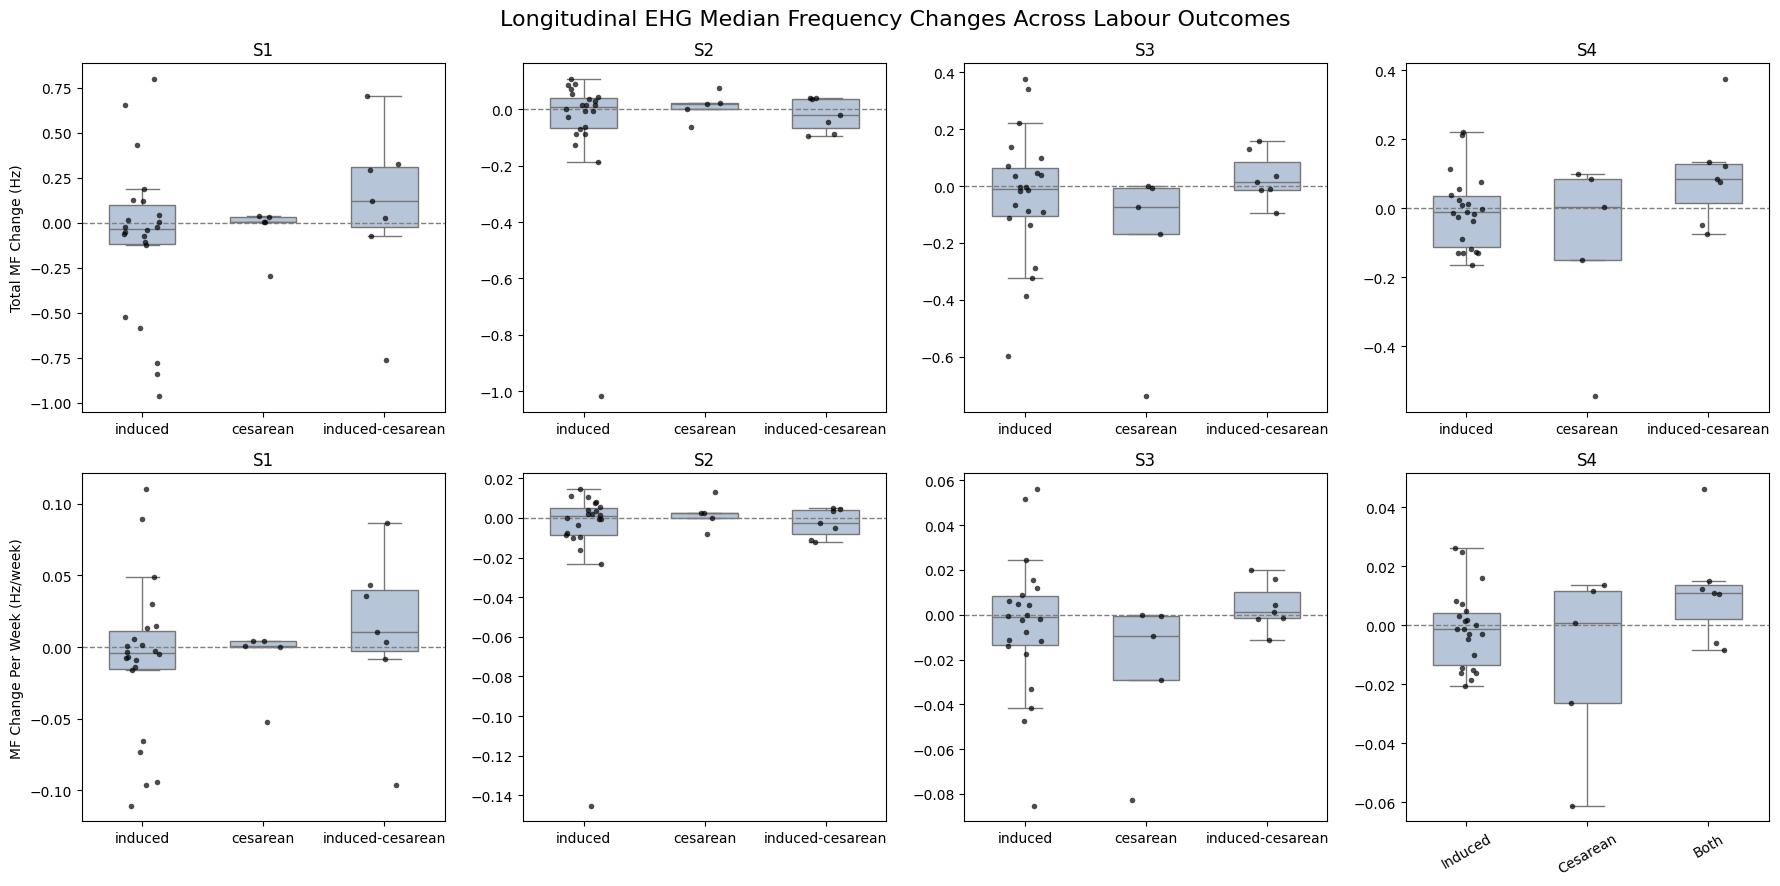

In [4]:

# Figure 1: Longitudinal EHG Median Frequency Changes by Labour Outcome

import matplotlib.pyplot as plt
import seaborn as sns

channels = ["S1", "S2", "S3", "S4"]
outcome_order = ["induced", "cesarean", "induced-cesarean"]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for row, (metric, ylabel) in enumerate([
    ("change", "Total MF Change (Hz)"),
    ("change_per_week", "MF Change Per Week (Hz/week)")
]):
    for col, channel in enumerate(channels):

        ax = axes[row, col]
        column = f"{channel}_{metric}"

        sns.boxplot(
            data=df_combined,
            x="outcome",
            y=column,
            order=outcome_order,
            showfliers=False,
            color="lightsteelblue",
            width=0.55,
            ax=ax
        )

        sns.stripplot(
            data=df_combined,
            x="outcome",
            y=column,
            order=outcome_order,
            color="black",
            size=4,
            jitter=0.15,
            alpha=0.7,
            ax=ax
        )

        ax.axhline(0, color="gray", linestyle="--", linewidth=1)

        ax.set_title(channel)
        ax.set_xlabel("")
        ax.set_ylabel(ylabel if col == 0 else "")
        ax.set_xticks([0, 1, 2])
ax.set_xticklabels(
    ["Induced", "Cesarean", "Both"],
    rotation=30
        )

plt.suptitle(
    "Longitudinal EHG Median Frequency Changes Across Labour Outcomes",
    fontsize=16
)

plt.tight_layout()
plt.show()




### Figure 2. Pairwise Differences in Median EHG Frequency Changes Across Labour Outcomes.

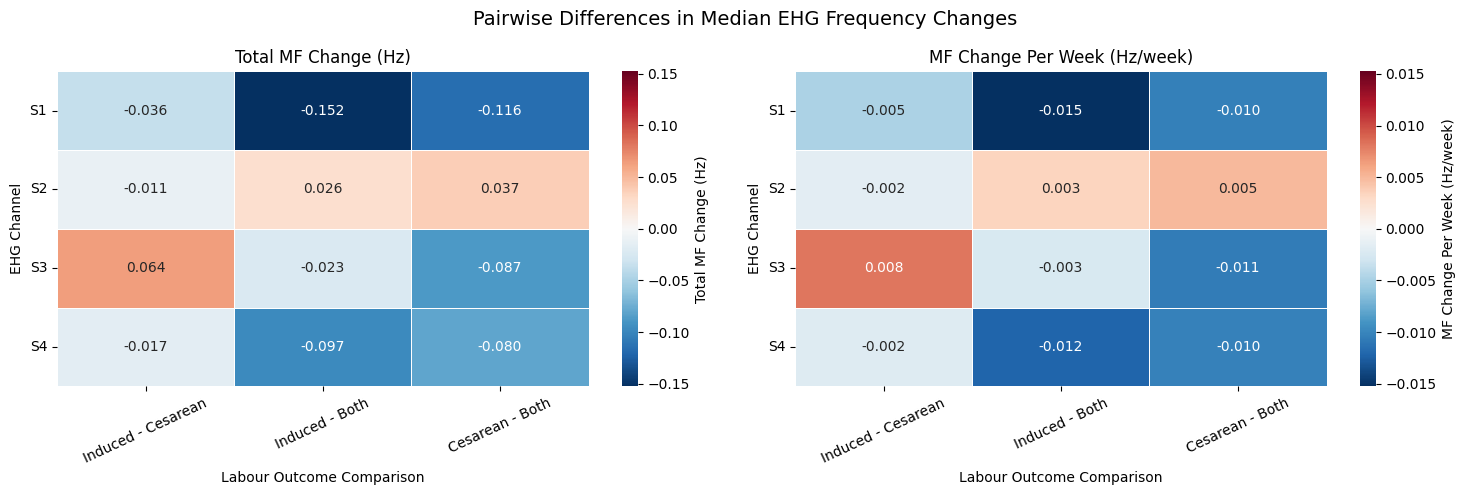

In [5]:

# Figure 2: Pairwise Differences in Median MF Changes

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

channels = ["S1", "S2", "S3", "S4"]

comparisons = [
    ("induced", "cesarean", "Induced - Cesarean"),
    ("induced", "induced-cesarean", "Induced - Both"),
    ("cesarean", "induced-cesarean", "Cesarean - Both")
]

metrics = [
    ("change", "Total MF Change (Hz)"),
    ("change_per_week", "MF Change Per Week (Hz/week)")
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (metric, title) in zip(axes, metrics):

    results = []

    for channel in channels:
        column = f"{channel}_{metric}"

        medians = df_combined.groupby("outcome")[column].median()

        row = {"Channel": channel}

        for group1, group2, label in comparisons:
            row[label] = medians[group1] - medians[group2]

        results.append(row)

    heatmap_data = pd.DataFrame(results).set_index("Channel")

    # Independent colour scale for each heatmap
    max_abs = abs(heatmap_data.to_numpy()).max()

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".3f",
        cmap="RdBu_r",
        center=0,
        vmin=-max_abs,
        vmax=max_abs,
        linewidths=0.5,
        cbar_kws={"label": title},
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Labour Outcome Comparison")
    ax.set_ylabel("EHG Channel")
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle(
    "Pairwise Differences in Median EHG Frequency Changes",
    fontsize=14
)

plt.tight_layout()
plt.show()



### Statistical Testing of MF Changes Across Labour Outcomes (Kruskal-Wallis)

In [6]:

# Kruskal-Wallis Statistical Analysis

import numpy as np
import pandas as pd
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

channels = ["S1", "S2", "S3", "S4"]

metrics = {
    "change": "Total MF Change",
    "change_per_week": "MF Change Per Week"
}

outcomes = ["induced", "cesarean", "induced-cesarean"]

results = []

for metric, metric_label in metrics.items():
    for channel in channels:

        column = f"{channel}_{metric}"

        # Separate measurements into the three outcome groups
        groups = [
            df_combined.loc[
                df_combined["outcome"] == outcome,
                column
            ].dropna()
            for outcome in outcomes
        ]

        # Kruskal-Wallis test
        H, p = kruskal(*groups)

        # Sample size and number of groups
        n = sum(len(group) for group in groups)
        k = len(groups)

        # Epsilon-squared effect size
        epsilon_sq = max(0, (H - k + 1) / (n - k))

        results.append({
            "Channel": channel,
            "Metric": metric_label,
            "N": n,
            "H Statistic": H,
            "p-value": p,
            "Effect Size (ε²)": epsilon_sq
        })

# Create statistical results table
df_stats = pd.DataFrame(results)

# Holm correction across all 8 tests
df_stats["Adjusted p-value"] = multipletests(
    df_stats["p-value"],
    method="holm"
)[1]

# Identify statistically significant results
df_stats["Significant"] = (
    df_stats["Adjusted p-value"] < 0.05
)

print("Kruskal-Wallis Statistical Results")
display(df_stats.round(4))


Kruskal-Wallis Statistical Results


,Channel,Metric,N,H Statistic,p-value,Effect Size (ε²),Adjusted p-value,Significant
0,S1,Total MF Change,34,1.7531,0.4162,0.0000,1.0,False
1,S2,Total MF Change,34,0.5062,0.7764,0.0000,1.0,False
2,S3,Total MF Change,34,2.6652,0.2638,0.0215,1.0,False
3,S4,Total MF Change,34,3.6049,0.1649,0.0518,1.0,False
4,S1,MF Change Per Week,34,1.5300,0.4653,0.0000,1.0,False
5,S2,MF Change Per Week,34,0.6870,0.7093,0.0000,1.0,False
6,S3,MF Change Per Week,34,2.8668,0.2385,0.0280,1.0,False
7,S4,MF Change Per Week,34,3.1444,0.2076,0.0369,1.0,False


### Pairwise comparisons between labour outcomes

Exploratory Pairwise Comparisons


,Channel,Metric,Comparison,Effect Size,Absolute Effect Size,p-value,Adjusted p-value
0,S1,Total MF Change,Induced vs Cesarean,-0.1091,0.1091,0.7394,1.0
1,S1,Total MF Change,Induced vs Both,-0.3117,0.3117,0.2370,1.0
2,S1,Total MF Change,Cesarean vs Both,-0.3714,0.3714,0.3434,1.0
3,S2,Total MF Change,Induced vs Cesarean,-0.1636,0.1636,0.5957,1.0
4,S2,Total MF Change,Induced vs Both,0.1039,0.1039,0.7023,1.0
5,S2,Total MF Change,Cesarean vs Both,0.2000,0.2000,0.6389,1.0
6,S3,Total MF Change,Induced vs Cesarean,0.3455,0.3455,0.2572,1.0
7,S3,Total MF Change,Induced vs Both,-0.1883,0.1883,0.4755,1.0
8,S3,Total MF Change,Cesarean vs Both,-0.6000,0.6000,0.1061,1.0
9,S4,Total MF Change,Induced vs Cesarean,0.0545,0.0545,0.8799,1.0


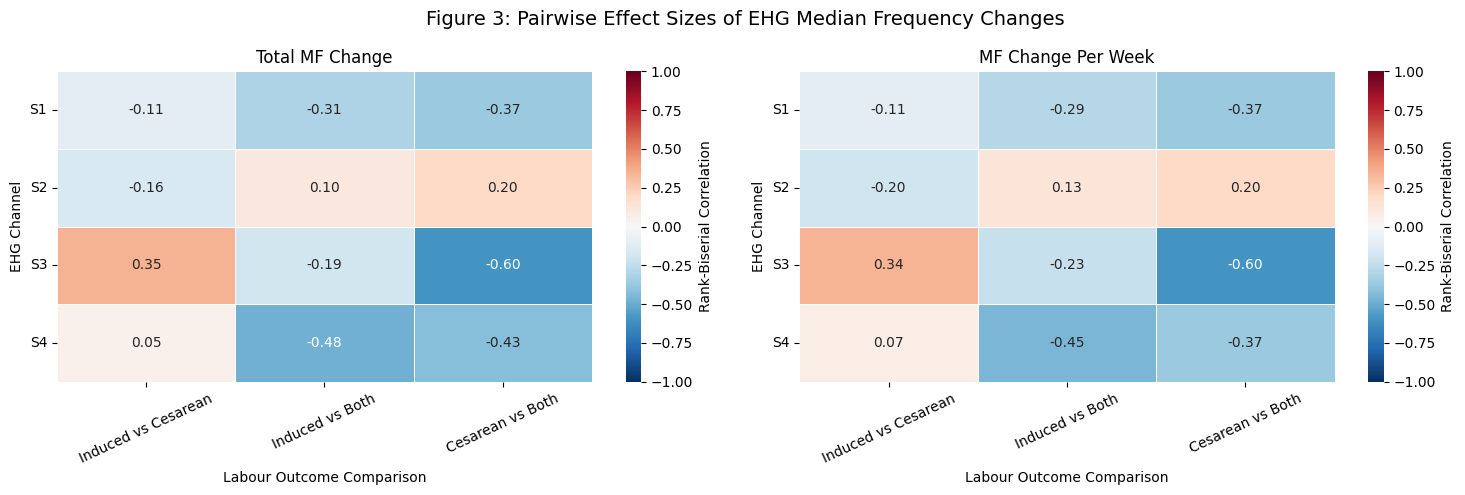

In [7]:

# Pairwise Effect Sizes Between Labour Outcomes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

channels = ["S1", "S2", "S3", "S4"]

comparisons = [
    ("induced", "cesarean", "Induced vs Cesarean"),
    ("induced", "induced-cesarean", "Induced vs Both"),
    ("cesarean", "induced-cesarean", "Cesarean vs Both")
]

metrics = {
    "change": "Total MF Change",
    "change_per_week": "MF Change Per Week"
}

results = []

for metric, metric_label in metrics.items():
    for channel in channels:
        column = f"{channel}_{metric}"

        for group1, group2, label in comparisons:

            x = df_combined.loc[
                df_combined["outcome"] == group1, column
            ].dropna()

            y = df_combined.loc[
                df_combined["outcome"] == group2, column
            ].dropna()

            # Mann-Whitney U test
            U, p = mannwhitneyu(
                x, y, alternative="two-sided"
            )

            # Signed rank-biserial correlation
            r = 2 * U / (len(x) * len(y)) - 1

            results.append({
                "Channel": channel,
                "Metric": metric_label,
                "Comparison": label,
                "Effect Size": r,
                "Absolute Effect Size": abs(r),
                "p-value": p
            })

df_pairwise = pd.DataFrame(results)

# Holm correction across all 24 comparisons
df_pairwise["Adjusted p-value"] = multipletests(
    df_pairwise["p-value"],
    method="holm"
)[1]

print("Exploratory Pairwise Comparisons")
display(df_pairwise.round(4))


# Figure 3: Pairwise Effect Sizes Across EHG Channels

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, metric_label in zip(
    axes,
    ["Total MF Change", "MF Change Per Week"]
):

    plot_data = df_pairwise[
        df_pairwise["Metric"] == metric_label
    ]

    heatmap_data = plot_data.pivot(
        index="Channel",
        columns="Comparison",
        values="Effect Size"
    )

    heatmap_data = heatmap_data[
        ["Induced vs Cesarean",
         "Induced vs Both",
         "Cesarean vs Both"]
    ].reindex(channels)

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        cbar_kws={"label": "Rank-Biserial Correlation"},
        ax=ax
    )

    ax.set_title(metric_label)
    ax.set_xlabel("Labour Outcome Comparison")
    ax.set_ylabel("EHG Channel")
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle(
    "Figure 3: Pairwise Effect Sizes of EHG Median Frequency Changes",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [8]:
for channel in ["S1", "S2", "S3", "S4"]:

    paired = df_combined[
        [f"{channel}_early_MF", f"{channel}_later_MF"]
    ].dropna()

    change = paired[f"{channel}_later_MF"] - paired[f"{channel}_early_MF"]

    q1 = change.quantile(0.25)
    q3 = change.quantile(0.75)
    iqr = q3 - q1

    print(f"{channel}: IQR = {iqr:.4f} Hz "
          f"(Q1 = {q1:.4f}, Q3 = {q3:.4f})")

S1: IQR = 0.2180 Hz (Q1 = -0.0994, Q3 = 0.1186)
S2: IQR = 0.1019 Hz (Q1 = -0.0641, Q3 = 0.0378)
S3: IQR = 0.1385 Hz (Q1 = -0.0953, Q3 = 0.0432)
S4: IQR = 0.1696 Hz (Q1 = -0.0862, Q3 = 0.0834)
